In [11]:
%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
import random
from gym_lattice.envs import Lattice2DEnv
from stable_baselines3 import DQN, PPO
from benchmark_callback import BenchmarkRewardCallback
import math

# HHHH x
# HHHP
# HHPH x
# HHPP
# HPHH x
# HPHP
# HPPH x
# HPPP
# PHHH
# PHHP
# PHPH
# PHPP
# PPHH
# PPHP
# PPPH
# PPPP
# 2/4 * 1/4 * 4/16

def random_seq_fn(length):
    return ''.join(random.choices('HP', k=length))

length = 30
ratio = 0.7
hs = math.floor(ratio * length)
ps = length - hs
seq = list('H' * hs + 'P' * ps)

def shuffle_seq_fn():
    random.shuffle(seq)
    return ''.join(seq)

env = Lattice2DEnv(
    15,
    shuffle_seq_fn,
    center_tail=True,
    distance_penalty=0.01,
    collision_penalty=-0.5,
    render_crop=0.5,
    lookahead=15
)


In [13]:

model_ppo = PPO(
    "MlpPolicy",
    env,
    learning_rate=0.0001,
    # policy_kwargs={"net_arch": [100, 10]},
    tensorboard_log="_logs",
    ent_coef=0.001
)

In [14]:
model_ppo.learn(
    total_timesteps=500_000,
    tb_log_name="PPO",
    callback=BenchmarkRewardCallback("benchmark.txt", env)
)

/Users/oliver/uni/protein/gym-lattice/gym_lattice/envs/lattice2d_env.py:213: UserWarning: WARN: Your agent was trapped! Ending the episode.
  logger.warn('Your agent was trapped! Ending the episode.')


In [25]:
model_dqn = DQN(
    "MlpPolicy",
    env,
    tensorboard_log="_logs",
    exploration_fraction=0.5,
    exploration_initial_eps=0.1,
    buffer_size=200_000
    # policy_kwargs={"net_arch": [100, 10]}
)
model_dqn.load("dqn.model")
model_dqn.load_replay_buffer("dqn.model.buffer")

In [ ]:
model_dqn.learn(
    total_timesteps=500_000,
    tb_log_name="DQN",
    callback=BenchmarkRewardCallback("benchmark.txt", env)
)


In [20]:
model_dqn.save("dqn.model")
model_dqn.save_replay_buffer("dqn.model.buffer")

In [17]:
print(env.grid_length)

21


21
(21, 21)
Solving for: HHPPPPPHHPPPHPPPHP

***********
***********
***********
***********
***********
*****H*****
***********
***********
***********
***********
***********
  (Up)
***********
***********
***********
***********
***********
*****H*****
*****H*****
***********
***********
***********
***********
  (Up)
***********
***********
***********
***********
*****P*****
*****H*****
*****H*****
***********
***********
***********
***********
  (Up)
***********
***********
***********
***********
*****P*****
*****P*****
*****H*****
*****H*****
***********
***********
***********
  (Up)
***********
***********
***********
*****P*****
*****P*****
*****P*****
*****H*****
*****H*****
***********
***********
***********
  (Right)
***********
***********
***********
*****PP****
*****P*****
*****P*****
*****H*****
*****H*****
***********
***********
***********
  (Right)
***********
***********
***********
****PPP****
****P******
****P******
****H******
****H******
***********
*******

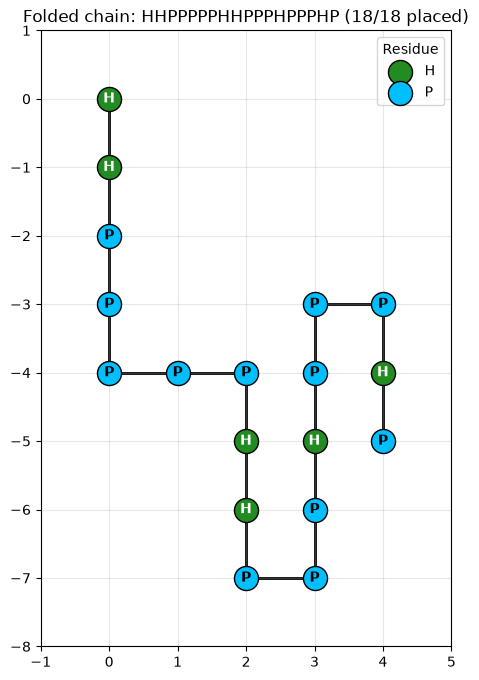

In [35]:
# loaded_model = PPO.load("17_decent.model")
print(env.grid_length)
print(env.grid.shape)
model = model_ppo
# print(obs.shape)
import matplotlib.pyplot as plt

def run_with_seq(seq: str):
    env.seq_fn = lambda: seq
    obs, _ = env.reset()
    print("Solving for:", env.seq)
    env.render()
    while not env.done:
        # Random agent samples from action space
        action, _ = model.predict(obs)
        obs, reward, terminated, truncated, info = env.step(int(action))
        env.render()
        if terminated or truncated:
            print("Episode finished! Reward: {} | Collisions: {} | Actions: {}".format(reward, info['collisions'], info['actions']))
            break

    coordinates = list(env.state)
    residues = list(env.state.values())
    x_coords, y_coords = zip(*coordinates)
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.plot(x_coords, y_coords, color="black", linewidth=2, zorder=1)
    for residue, color in (("H", "forestgreen"), ("P", "deepskyblue")):
        points = [(x, y) for (x, y), value in zip(coordinates, residues) if value == residue]
        if points:
            points_x, points_y = zip(*points)
            ax.scatter(points_x, points_y, color=color, edgecolors="black", s=300, label=residue, zorder=2)
    for x, y, residue in zip(x_coords, y_coords, residues):
        text_color = "white" if residue == "H" else "black"
        ax.text(x, y, residue, ha="center", va="center", color=text_color, weight="bold", zorder=3)
    ax.set_xticks(range(min(x_coords) - 1, max(x_coords) + 2))
    ax.set_yticks(range(min(y_coords) - 1, max(y_coords) + 2))
    ax.grid(True, alpha=0.3)
    ax.set_aspect("equal")
    ax.legend(title="Residue")
    ax.set_title(f"Folded chain: {env.seq} ({len(residues)}/{len(env.seq)} placed)")
    plt.show()

run_with_seq("hhppppphhppphppphp".upper())

# for i_episodes in range(3):
#     run_with_seq(random_seq_fn(10))

In [19]:
env2 = Lattice2DEnv(6, lambda:'HPH', center_tail=True)
env2.reset()
env2.seq = "HPHPH"
env2.step(3)
env2.render()
env2.step(2)
env2.step(0)
env2.render()
print(env.step(0))
# env.step(3)
env2.render()
# env.step(3)
# env.step(3)
# env.step(1)
# env.step(1)
# grid, _, _, _, _ = env.step(3)

  (Right)
*************
*************
*************
*************
*************
*************
*****HP******
*************
*************
*************
*************
*************
*************
  (Left)
*************
*************
*************
*************
*************
*************
******PH*****
******HP*****
*************
*************
*************
*************
*************
(array([1, 0, 0, ..., 1, 0, 0], shape=(1353,)), -9.55, True, False, {'chain_length': 18, 'seq_length': 18, 'collisions': 1, 'actions': ['U', 'R', 'R', 'U', 'L', 'L', 'U', 'R', 'R', 'U', 'L', 'U', 'R', 'R', 'D', 'D', 'D'], 'is_trapped': True, 'state_chain': OrderedDict({(0, 0): 'H', (0, -1): 'H', (1, -1): 'P', (2, -1): 'P', (2, -2): 'P', (1, -2): 'P', (0, -2): 'P', (0, -3): 'H', (1, -3): 'H', (2, -3): 'P', (2, -4): 'P', (1, -4): 'P', (1, -5): 'H', (2, -5): 'P', (3, -5): 'P', (3, -4): 'P', (3, -3): 'H', (3, -2): 'P'})})
  (Left)
*************
*************
*************
*************
*************
*************
